In [1]:
from sklearn.datasets import fetch_openml

In [2]:
cifar10 = fetch_openml(name='cifar_10')

In [3]:
cifar10.data

,a0,a1,a2,a3,a4,a5,a6,a7,a8,a9,...,a3062,a3063,a3064,a3065,a3066,a3067,a3068,a3069,a3070,a3071
0,26,17,13,13,13,14,14,15,14,10,...,250,237,144,33,29,46,28,27,26,27
1,94,101,95,94,94,97,111,142,166,154,...,149,145,147,150,152,163,174,182,184,155
2,183,158,166,167,169,171,163,163,160,161,...,186,174,177,227,250,250,250,250,250,250
3,255,254,255,255,255,255,255,255,255,255,...,255,255,255,255,255,255,255,255,255,255
4,182,156,156,144,118,132,148,118,136,85,...,87,83,83,75,79,72,68,73,67,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,76,76,77,76,75,76,76,76,76,78,...,228,185,177,223,239,239,235,236,234,236
59996,81,91,98,106,108,110,80,84,88,90,...,126,107,143,155,156,160,173,129,147,160
59997,20,19,15,15,14,13,12,11,10,9,...,114,112,68,50,52,52,51,50,53,47
59998,25,15,23,17,23,51,74,91,114,137,...,87,84,83,84,79,78,78,80,81,80


In [27]:
image_data = cifar10.data.iloc[2].values
image_data.shape

(3072,)

In [28]:
red_channel = image_data[:1024].reshape(32,32)
red_channel

array([[183, 158, 166, ..., 142, 137, 144],
       [125,  97, 100, ...,  63,  59,  67],
       [107,  85,  88, ...,  63,  53,  60],
       ...,
       [108,  98, 119, ..., 114, 104,  91],
       [199, 197, 207, ..., 203, 200, 189],
       [251, 248, 249, ..., 250, 250, 250]])

In [29]:
green_channel = image_data[1024:2048].reshape(32,32)
green_channel

array([[186, 167, 172, ..., 147, 146, 150],
       [134, 111, 112, ...,  74,  74,  79],
       [121, 104, 104, ...,  79,  73,  77],
       ...,
       [116, 107, 130, ..., 125, 115, 101],
       [205, 203, 214, ..., 209, 205, 194],
       [255, 252, 253, ..., 251, 250, 251]])

In [30]:
blue_channel = image_data[2048:].reshape(32,32)
blue_channel

array([[178, 152, 160, ..., 144, 141, 146],
       [120,  90,  95, ...,  68,  67,  72],
       [103,  79,  83, ...,  71,  64,  69],
       ...,
       [103,  87, 105, ..., 113, 103,  90],
       [197, 190, 196, ..., 202, 199, 188],
       [252, 246, 244, ..., 250, 250, 250]])

In [31]:
import numpy as np
rgb_image = np.stack([red_channel, green_channel, blue_channel], axis=2)
rgb_image.shape

(32, 32, 3)

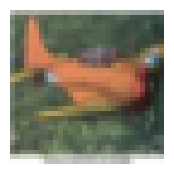

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(2,2))
plt.imshow(rgb_image)
plt.axis('off')
plt.show()

In [33]:
cifar10.target

0        8
1        5
2        0
3        6
4        9
        ..
59995    8
59996    3
59997    5
59998    1
59999    7
Name: class, Length: 60000, dtype: category
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [34]:
cifar10.target.cat.codes

0        8
1        5
2        0
3        6
4        9
        ..
59995    8
59996    3
59997    5
59998    1
59999    7
Length: 60000, dtype: int8

In [35]:
cifar10.target.cat.categories

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='object')

In [36]:
cifar10.target.cat.categories[8]

'8'

In [42]:
images_flat = cifar10.data.values
images_flat.shape

(60000, 3072)

In [43]:
images_channels = images_flat.reshape(60000, 3, 1024)
images_channels.shape

(60000, 3, 1024)

In [44]:
images_channels_grid = images_channels.reshape(60000, 3, 32, 32)
images_channels_grid.shape

(60000, 3, 32, 32)

In [45]:
images_final = np.transpose(images_channels_grid, (0, 2, 3, 1))
images_final.shape

(60000, 32, 32, 3)

In [53]:
labels_final = cifar10.target.to_numpy()
labels_final.shape

(60000,)

In [59]:
from sklearn.model_selection import train_test_split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(images_final, labels_final, random_state=42, train_size=50000, stratify=labels_final)

In [58]:
X_train_raw.shape

(50000, 32, 32, 3)

In [60]:
X_test_raw.shape

(10000, 32, 32, 3)